# Week 3: Where does a CXR model look?

See `week3/README-kopi.md` for the task. We have three trained DenseNet-121 models (Cardiomegaly, Edema, Atelectasis). Each gives **one logit**, and higher means "positive finding". No training is needed.

We use **Grad-CAM** to see which image regions push that logit up, and then run four tests:
1. Compare the three models on the same images
2. Cardiomegaly: positive vs negative images
3. Atelectasis: does added text ("PORTABLE AP") change the score?
4. Cardiomegaly: hide the heart vs hide a lung region

## Setup

Run from `week3/`, so `load_model.py` and `images/` are found directly.

In [31]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image, ImageDraw, ImageFont

from load_model import load_model, preprocess

IMG = Path("images")
info = pd.read_csv("images.csv")
models = {name: load_model(name) for name in ["Cardiomegaly", "Edema", "Atelectasis"]}

## Grad-CAM

DenseNet works in two parts:
- `model.features(x)`: turns the 256×256 image into **1024 feature maps of 8×8**. Each cell of the 8×8 grid covers about a 32×32 pixel patch.
- then ReLU → average over the grid → `classifier` → one logit.

Our **target layer** is the output of `model.features`: the last spatial layer before everything is averaged away.

Grad-CAM in 3 steps:
1. Take the gradient of the logit with respect to the feature maps: "if this map gets stronger, does the logit go up?"
2. Average each map's gradient into one **weight** per map.
3. Heatmap = ReLU(weighted sum of the maps). We keep only the regions that push the logit **up**.

Tiny example: if map A is active over the heart and has weight +0.5, and map B is active over the shoulder with weight −0.2, the heatmap lights up the heart, and the shoulder becomes 0 after the ReLU.

We run the forward pass by hand (the same steps as `model.forward`), so we can keep the feature maps. No `torch.no_grad()`, because we need gradients.

In [32]:
def gradcam(model, x):
    feats = model.features(x)              # [1, 1024, 8, 8]
    feats.retain_grad()                    # keep its gradient after backward()
    pooled = F.adaptive_avg_pool2d(F.relu(feats), 1).flatten(1)
    logit = model.classifier(pooled)[0, 0]  # the positive logit
    logit.backward()

    weights = feats.grad.mean(dim=(2, 3), keepdim=True)  # one weight per map
    cam = F.relu((weights * feats).sum(dim=1))[0]        # [8, 8]
    cam = cam / (cam.max() + 1e-8)                       # scale to 0..1 for plotting
    return logit.item(), cam.detach().numpy()


def show(ax, image, cam, title):
    """Image with the 8x8 heatmap stretched to 256x256 on top."""
    ax.imshow(image.convert("L").resize((256, 256)), cmap="gray")
    ax.imshow(cam, cmap="jet", alpha=0.4, extent=(0, 256, 256, 0), interpolation="bilinear")
    ax.set_title(title, fontsize=9)
    ax.axis("off")

Quick check: our hand-made forward pass should give the **same** logit as `model(x)`, and the score should match `python load_model.py` (0.9546).

model(x): 3.0459675788879395
gradcam : 3.0459675788879395 -> score 0.9546080827713013


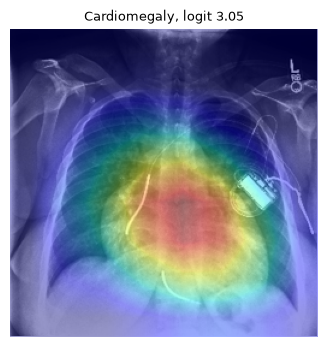

In [33]:
image = Image.open(IMG / "02_positive_negative/02_01_original.jpg").convert("RGB")
x = preprocess(image)
model = models["Cardiomegaly"]

logit, cam = gradcam(model, x)
print("model(x):", model(x)[0, 0].item())
print("gradcam :", logit, "-> score", torch.sigmoid(torch.tensor(logit)).item())

fig, ax = plt.subplots(figsize=(4, 4))
show(ax, image, cam, f"Cardiomegaly, logit {logit:.2f}")
plt.show()

## Test 1: Does the map change with the pathology?

Same 3 images, all 3 models: rows = images, columns = models.

In each title:
- **logit / score:** what the model says
- **label:** what `images.csv` says (1 = positive, -1 = uncertain, blank = not mentioned)

All 3 images are labelled positive for Cardiomegaly and Atelectasis. Edema is positive in 01_02 and 01_03, and uncertain in 01_01.

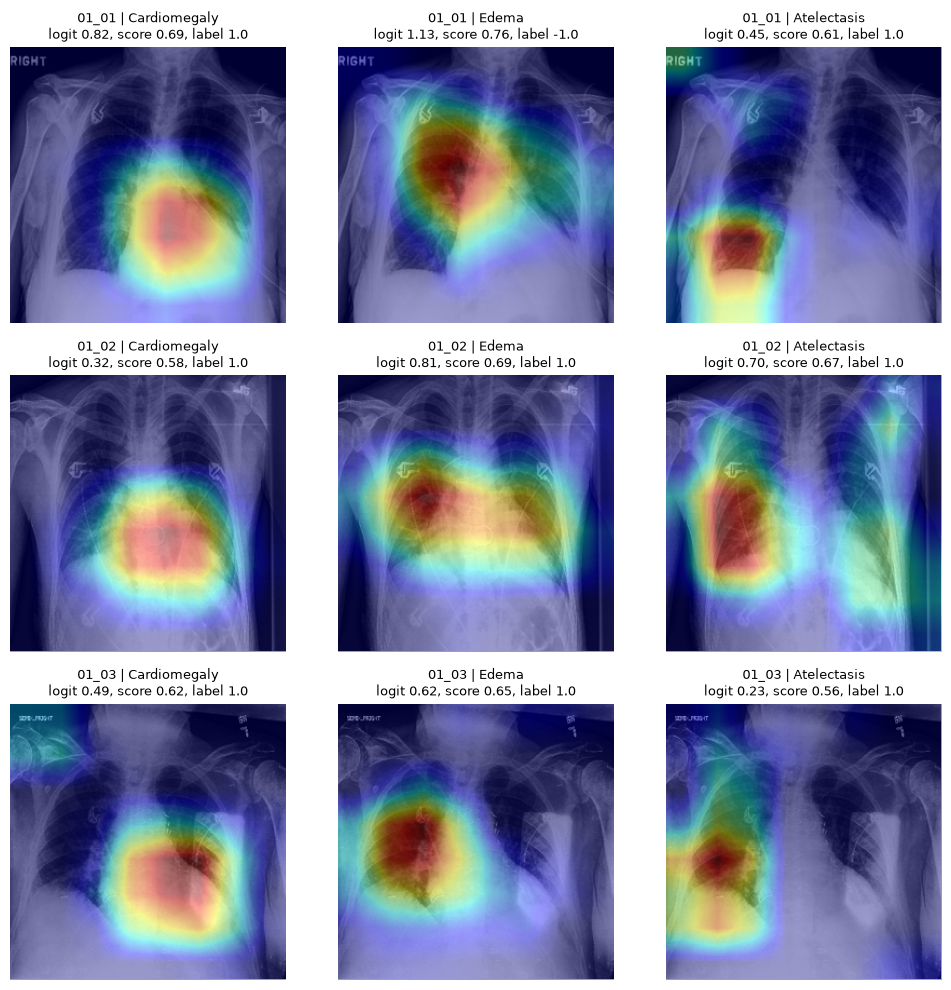

In [34]:
names = ["01_01", "01_02", "01_03"]
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

for i, name in enumerate(names):
    image = Image.open(IMG / f"01_compare_models/{name}_original.jpg").convert("RGB")
    x = preprocess(image)
    row = info[info.image_id == f"{name}_original"].iloc[0]
    for j, (pathology, model) in enumerate(models.items()):
        logit, cam = gradcam(model, x)
        score = torch.sigmoid(torch.tensor(logit)).item()
        show(axes[i, j], image, cam,
             f"{name} | {pathology}\nlogit {logit:.2f}, score {score:.2f}, label {row[pathology]}")

plt.tight_layout()
plt.show()

**What to look for**
- Cardiomegaly: is the map on the heart (lower middle, slightly left on the image's right side)?
- Edema: is it spread across both lungs, maybe near the hila (where the vessels enter the lungs)?
- Atelectasis: is it at the lung bases or lower lobes?
- Does the *same* image get *different* maps from different models? If all 3 maps look the same, the model might be looking at something general (e.g. "this is a sick patient") instead of the specific finding.

**My notes:**
In 01_01, Edema is labelled uncertain (-1), but its score (0.76) is the highest of the three models. What does that tell you about using the label as the "truth" here?

- *So for 01_01 we don't know whether there is edema. A score of 0.76 is neither clearly right nor clearly wrong.
Also, the original study trained with uncertain counted as positive. So the model was taught to say "yes" in cases like this.* - labels are noisy! not GT

The Cardiomegaly map is on the heart. Does that prove the model understands heart size? What else could the heart region tell the model? Hint: think about how these images were taken (AP/portable vs PA).

- *PA (posterior → anterior): the beam enters through the back and the detector is at the chest. The patient stands up in the X-ray room. This is the standard view for patients who are well enough.
AP (anterior → posterior): the beam enters through the front and the detector is behind the back. It's often a portable machine at the bedside, for patients who are too sick to stand. - The heart also carries clues about how the image was taken.*


## Test 2: Positive vs negative (Cardiomegaly model)

- Top row: 02_01–02_03, labelled **Cardiomegaly positive**
- Bottom row: 02_04–02_06, low-score comparisons. 04 and 06 are labelled **No Finding**; 05 has no positive label but also no explicit "No Finding".

The titles also show the **view** (AP/PA), because of the magnification effect from Test 1.

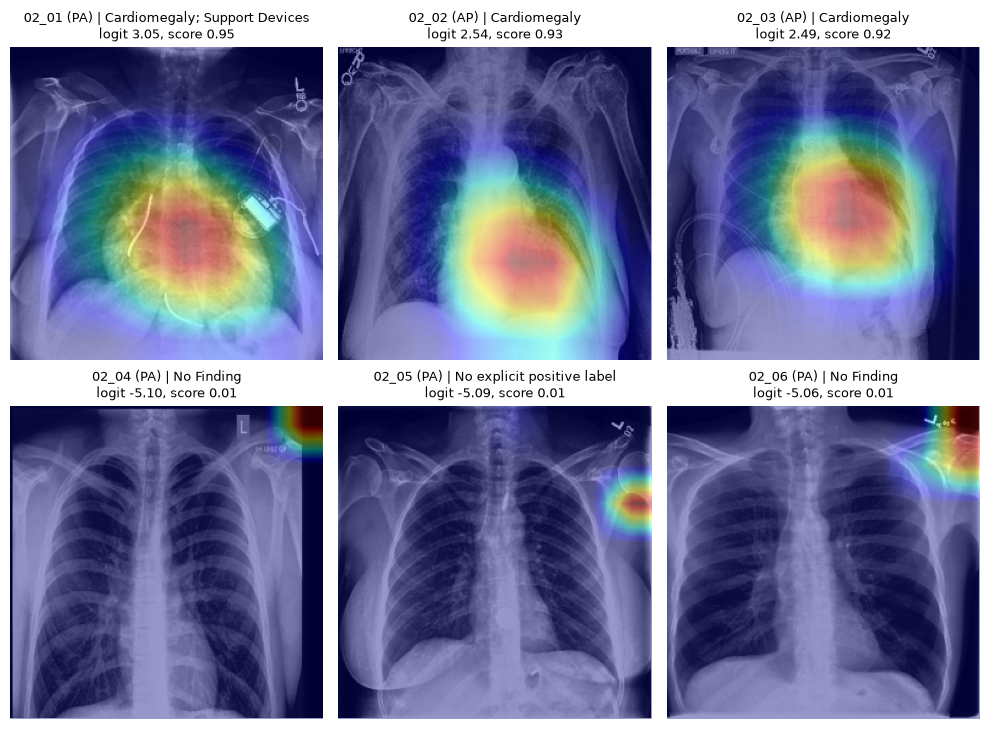

In [35]:
model = models["Cardiomegaly"]
fig, axes = plt.subplots(2, 3, figsize=(10, 7.5))

for ax, k in zip(axes.flat, range(1, 7)):
    name = f"02_0{k}"
    image = Image.open(IMG / f"02_positive_negative/{name}_original.jpg").convert("RGB")
    row = info[info.image_id == f"{name}_original"].iloc[0]
    logit, cam = gradcam(model, image_x := preprocess(image))
    score = torch.sigmoid(torch.tensor(logit)).item()
    show(ax, image, cam,
         f"{name} ({row.view}) | {row.positive_labels}\nlogit {logit:.2f}, score {score:.2f}")

plt.tight_layout()
plt.show()

"the little positive push that exists comes from here"

**Careful with the negatives:** Grad-CAM divides each map by its own maximum, so every map has a red spot, even when the score is very low. Always read the map **together with** the score. A red heart on a 0.05 image means "this is the region that pushes the logit up the most", not "the model sees cardiomegaly here".

**What to look for**
- Positives: is the heat on the heart, or also outside it (devices, edges, text)?
- Negatives: where does the (small) positive evidence sit?
- Is there a pattern with AP vs PA?

**My notes:**

So a fairer description: the heat sits in the top-right corner or shoulder area, near the marker, and away from the heart.

The warning is about what the model has learned. If the corner adds even a little to "cardiomegaly", then something in training linked corners, markers or image borders to the disease. A likely reason: marker style, border shape and placement depend on the hospital and the machine. Portable AP machines in intensive care, with sicker patients, produce different-looking corners than the standing PA room.

## Test 3: Text shortcut (Atelectasis model)

All 4 images are PA and labelled **No Finding**. The `_text.png` versions have white "PORTABLE AP" stamped in the top-left corner (at about x 9–125, y 9–20 on the 256×256 image). The label doesn't change, so a good model should give the same score.

**Why a control?** If the score goes up, there are two possible reasons:
- the **words**: the model learned that "PORTABLE AP" means sicker patients (a shortcut)
- just **added white pixels** in the corner: any change there moves the score

So we also draw our own text at the same spot, at about the same size:
- **my PORTABLE AP**: the same words in our font. This checks that our drawing reproduces the effect.
- **my HEJ MED DIG**: unrelated words of the same length (11 characters).

If PORTABLE AP raises the score much more than HEJ MED DIG, the effect depends on the words.

In [36]:
FONT = ImageFont.load_default(size=16)

def add_text(image, text):
    """Resize to 256x256 first (the edit happens before normalization), then draw white text top-left."""
    image = image.resize((256, 256), Image.Resampling.BILINEAR)
    ImageDraw.Draw(image).text((9, 9), text, font=FONT, fill="white", anchor="lt", stroke_width=1)
    return image

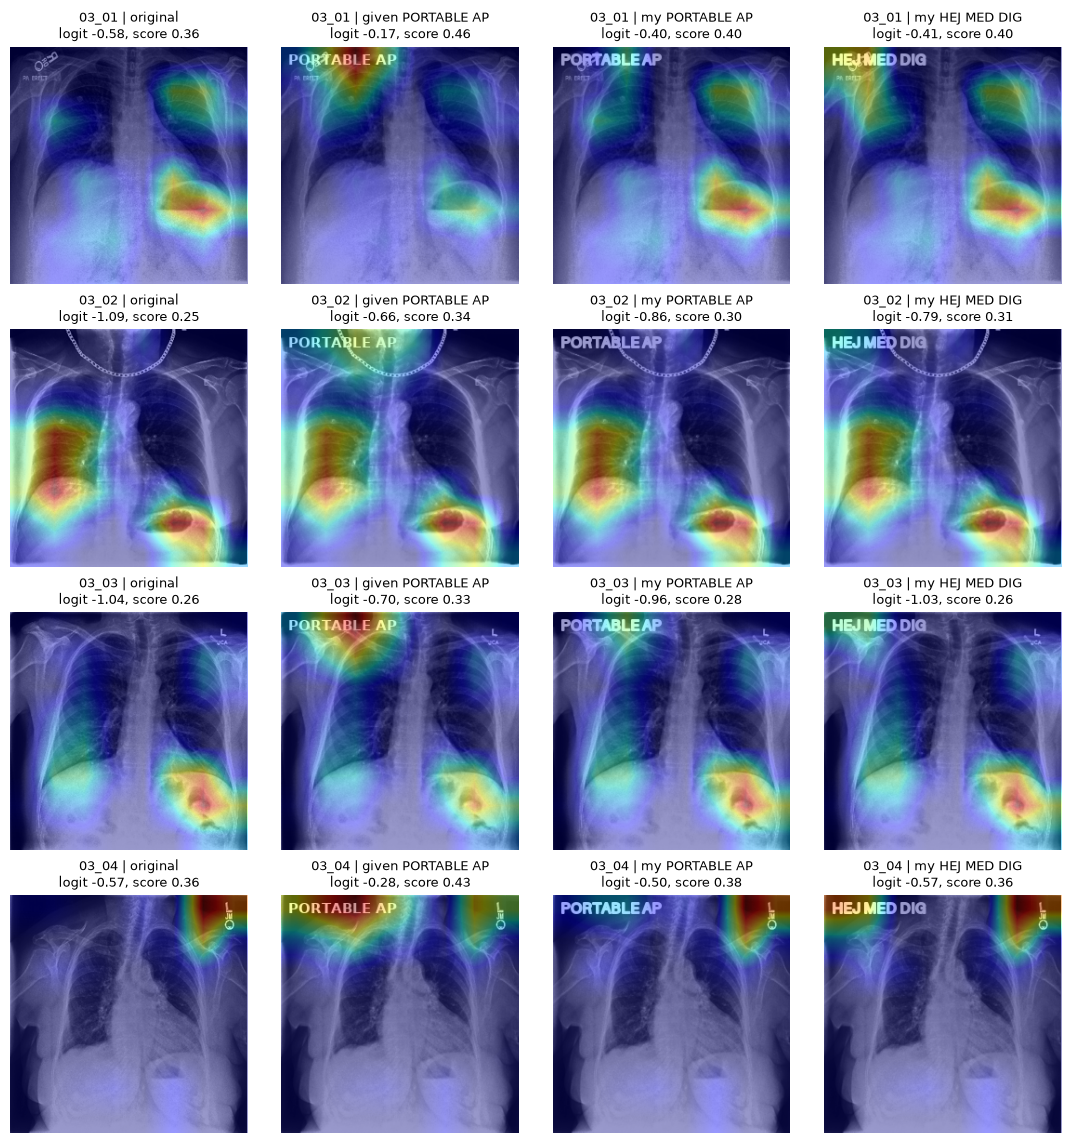

,original,given PORTABLE AP,my PORTABLE AP,my HEJ MED DIG
image,,,,
03_01,0.359,0.458,0.402,0.399
03_02,0.252,0.341,0.297,0.312
03_03,0.262,0.331,0.276,0.263
03_04,0.362,0.431,0.377,0.362


In [37]:
model = models["Atelectasis"]
fig, axes = plt.subplots(4, 4, figsize=(11, 11.5))
rows = []

for i, k in enumerate(range(1, 5)):
    original = Image.open(IMG / f"03_text_shortcut/03_0{k}_original.jpg").convert("RGB")
    variants = {
        "original": original,
        "given PORTABLE AP": Image.open(IMG / f"03_text_shortcut/03_0{k}_text.png").convert("RGB"),
        "my PORTABLE AP": add_text(original, "PORTABLE AP"),
        "my HEJ MED DIG": add_text(original, "HEJ MED DIG"),
    }
    row = {"image": f"03_0{k}"}
    for j, (variant, image) in enumerate(variants.items()):
        logit, cam = gradcam(model, preprocess(image))
        score = torch.sigmoid(torch.tensor(logit)).item()
        row[variant] = round(score, 3)
        show(axes[i, j], image, cam, f"03_0{k} | {variant}\nlogit {logit:.2f}, score {score:.2f}")
    rows.append(row)

plt.tight_layout()
plt.show()
pd.DataFrame(rows).set_index("image")

**What to look for**
- Does the score go up with "PORTABLE AP"? By how much compared with HEJ MED DIG?
- Does the heatmap move to the text corner?
- Remember Test 1: the real images there also had text markers ("RIGHT", "SEMI-UPRIGHT").

**My notes:**
The heatmap moves onto the text only for the given version, not for mine, even though mine also raises the score a little. What does that say about trusting heatmaps alone?
 - Answer: with my text, the score went up a little, but the heatmap did not move to the text. So a region can change the score without lighting up in the map. Grad-CAM is coarse (8×8), each map is scaled to its own maximum, and it only shows the strongest positive push.

Takeaway:

A heatmap can miss things that matter, and can highlight things that don't.
To find out what really affects the score, you have to change the image and measure, like we did in Test 3.

## Test 4: Hide the heart vs hide a lung (Cardiomegaly model)

Grad-CAM only shows *sensitivity*. Here we **change the image and measure**: cover a region with a black box and see how much the score drops.
- **Heart box:** if the model really uses the heart, the score should drop a lot.
- **Lung box (control):** also a black box, but away from the heart. If the score drops just as much, the drop comes from "a black box was added", not from losing the heart.
- **Big lung box (control):** the same size as the heart box (lung + ribs + edge), so box size can't explain the difference.

The boxes are `(x0, y0, x1, y1)` on the 256×256 image. **Check them in the preview and move them if you disagree.** You're the one drawing them.

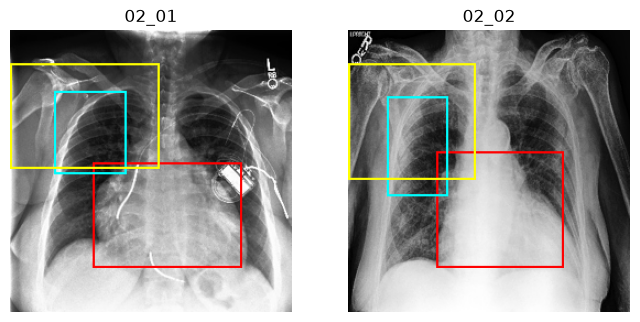

In [38]:
BOXES = {
    "02_01": {"heart": (75, 120, 210, 215), "lung": (40, 55, 105, 130), "big lung": (0, 30, 135, 125)},
    "02_02": {"heart": (80, 110, 195, 215), "lung": (35, 60, 90, 150), "big lung": (0, 30, 115, 135)},
}

def occlude(image, box):
    """Resize to 256x256 first (edit before normalization), then paint the box black."""
    image = image.resize((256, 256), Image.Resampling.BILINEAR)
    ImageDraw.Draw(image).rectangle(box, fill="black")
    return image

# Preview: red = heart box, cyan = lung box, yellow = big lung box (same size as heart)
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, (name, boxes) in zip(axes, BOXES.items()):
    image = Image.open(IMG / f"02_positive_negative/{name}_original.jpg").convert("RGB").resize((256, 256))
    draw = ImageDraw.Draw(image)
    draw.rectangle(boxes["heart"], outline="red", width=2)
    draw.rectangle(boxes["lung"], outline="cyan", width=2)
    draw.rectangle(boxes["big lung"], outline="yellow", width=2)
    ax.imshow(image)
    ax.set_title(name)
    ax.axis("off")
plt.show()

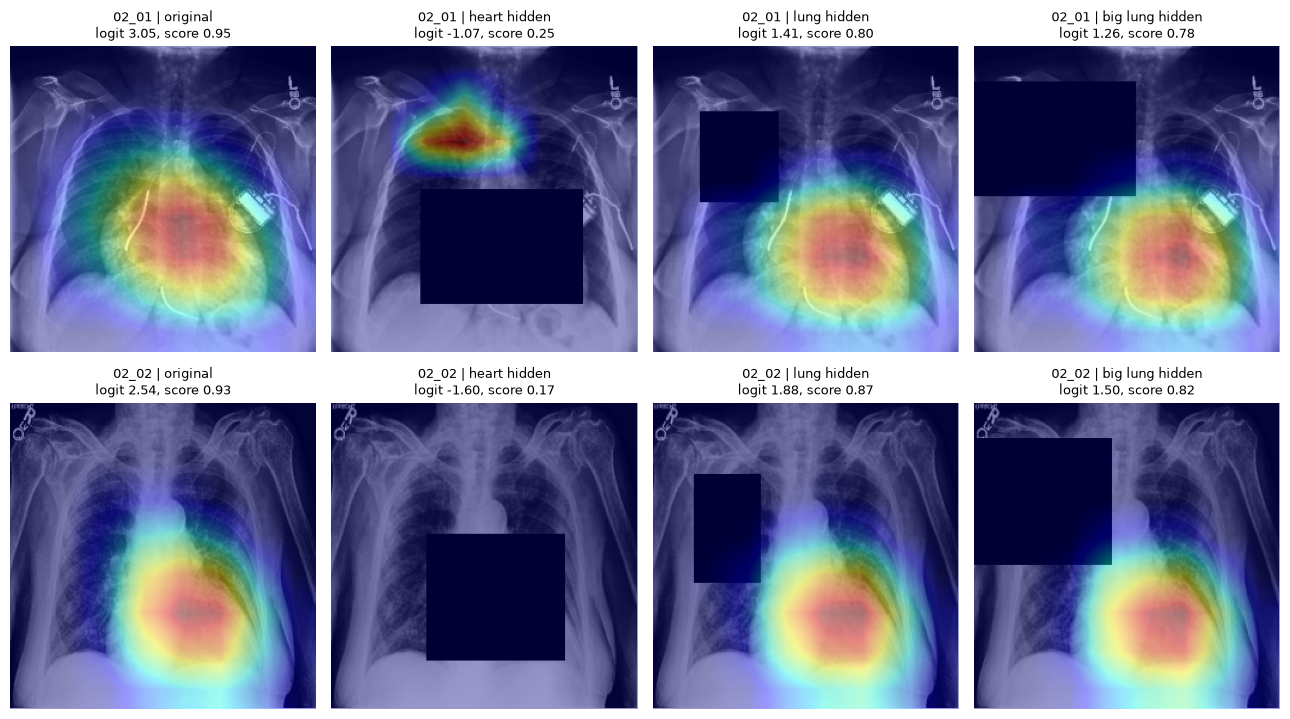

,original,heart hidden,lung hidden,big lung hidden
image,,,,
02_01,0.955,0.255,0.804,0.780
02_02,0.927,0.167,0.868,0.817


In [40]:
model = models["Cardiomegaly"]
fig, axes = plt.subplots(2, 4, figsize=(13, 7.5))
rows = []

for i, (name, boxes) in enumerate(BOXES.items()):
    original = Image.open(IMG / f"02_positive_negative/{name}_original.jpg").convert("RGB")
    variants = {
        "original": original,
        "heart hidden": occlude(original, boxes["heart"]),
        "lung hidden": occlude(original, boxes["lung"]),
        "big lung hidden": occlude(original, boxes["big lung"]),
    }
    row = {"image": name}
    for j, (variant, image) in enumerate(variants.items()):
        logit, cam = gradcam(model, preprocess(image))
        score = torch.sigmoid(torch.tensor(logit)).item()
        row[variant] = round(score, 3)
        show(axes[i, j], image, cam, f"{name} | {variant}\nlogit {logit:.2f}, score {score:.2f}")
    rows.append(row)

plt.tight_layout()
plt.show()
pd.DataFrame(rows).set_index("image")

**What to look for**
- How much does the score drop with the heart hidden vs the lung hidden?
- Where does the heatmap go once the heart is gone?
- In 02_01 the heart box also covers part of the pacemaker. Could that affect the result?

**My notes:**

imitations to put on the poster

My heart box is bigger than the lung box, about 2–3 times the area. Part of the bigger drop could come from simply more black pixels. A fairer control would use two boxes of the same size.
In 02_01 the heart box also covers part of the pacemaker. So we hid two things at once.
A black box is an unnatural image. The model never saw one in training, so the scores show "what happens with something strange", not "a heart that looks normal".
Look at the box preview in your notebook too. The task says "draw your own", so move the boxes if you disagree with where I put them.

Questions:

Should we make the lung box the same size as the heart box to fix limitation 1? (It doesn't fit inside one lung, so it would cover lung and ribs or the edge.) Or is noting the limitation on the poster enough?
Compare Test 3 and Test 4: in which test did the heatmap agree with what happened when we edited the image, and in which did it not?